# Preserving hard actuators while states yield

Level 2. Prerequisite: the scalar price lesson. Reading time: 35 minutes.

**Question:** Can a double-integrator controller preserve its actuator limits when the initial position already conflicts with its desired state interval?


## Objectives

A controller cannot repair its current position instantaneously. If its state begins outside a tight comfort region, enforcing every predicted state bound as hard can make the planning QP infeasible even though useful bounded controls exist. We will declare the actuator interval immutable and price state departures explicitly. The lesson concerns a synthetic optimization model; an engineering safety requirement would need a separate assessment of whether any chosen state row may yield.

We will solve one condensed horizon, inspect the physical predictions, compare independent formulations and update a prepared workspace for a subsequent state. These operations answer different questions: policy chooses the allowable trade-off, numerical verification checks the returned optimum, and workspace reuse changes execution organization. Neither a small objective gap nor a successful warm solve certifies the real plant.


## Setup

Use a separate Python 3.12 environment. The native engine is a separate distribution. Install the exact environment outside the notebook:

```bash
pip install "softqp==0.1.0"
pip install "numpy==2.5.4"
pip install "scipy==1.18.1"
pip install "matplotlib==3.11.2"
pip install "osqp==1.1.3"
pip install "daqp==0.10.3"
pip install "elastiqp==0.2.0"
```

The single setup cell resolves the repository, imports the methods and prints numerical versions. No installation runs inside a kernel.


In [1]:
# Resolve inputs once so every scientific cell focuses on the optimization.
from pathlib import Path
import sys
import json
import importlib.metadata
from dataclasses import replace
import numpy as np
import matplotlib.pyplot as plt
from softqp.solvers import solve
from softqp.flex import solve_flex
from softqp.elasti import solve_elastiqp
from softqp.sessions import PreparedSolver
candidates = [Path.cwd(), *Path.cwd().parents]
root = next(p for p in candidates if (p / "VERSION").is_file() and (p / "data-pipeline").is_dir())
sys.path.insert(0, str(root / "data-pipeline"))
from pipeline.softqp_cases import scalar, mpc
from pipeline.softqp_campaign import generated_problem, primary_endpoint
from pipeline.optimality import kkt
from pipeline.control import predict_states
for distribution in ("softqp", "numpy", "scipy", "matplotlib", "osqp", "daqp", "elastiqp"):
    print(distribution, importlib.metadata.version(distribution))
accurate = dict(eps_abs=1e-9, eps_rel=1e-9, adaptive_rho_interval=25)
plt.rcParams.update({"figure.dpi": 100, "font.size": 10})


softqp 0.1.0
numpy 2.5.4
scipy 1.18.1
matplotlib 3.11.2
osqp 1.1.3
daqp 0.10.3
elastiqp 0.2.0


## Data

The authored C12 initial horizon uses position 1.6 m, velocity zero, twenty control intervals and a sampling period of 0.2 s. Each acceleration stays in [-1,1] m/s². Desired position is within ±0.4 m and desired velocity within ±1.5 m/s. There are twenty hard actuator rows and forty soft state rows. Lower linear/quadratic prices are 0.3/2 and upper prices 1.2/4. The input comes from `mpc` in `data-pipeline/pipeline/softqp_cases.py`, not a measured industrial trajectory.


## Method

The discrete dynamics are $s_{k+1}=Fs_k+Bu_k$, with $F=[[1,0.2],[0,1]]$ and $B=[0.02,0.2]^\top$. Condensation substitutes these equations into all predicted states, leaving twenty controls as the optimization variables. The dynamics then hold by construction rather than through a large collection of approximate equality constraints. The state weights are 3 for position and 0.3 for velocity, with input weight 0.1, under the half-quadratic convention.

First run the asymmetric solver on the declared hard/soft mixture. Record hard-row error separately from state violation. Summing raw meters and meters per second would have no physical interpretation, so the exported row units and the figures keep those quantities apart. The original condensed objective omits a state-dependent constant; we will not mistake a negative value for a negative physical energy or tracking cost.


In [2]:
# The actuator mask remains hard while both state sides receive explicit prices.
problem = mpc(True, True, 1.6, 0.0)
native = solve(problem, "asymmetric", **accurate)
print("Variables / hard rows / soft rows:", problem.q.size,
      int((~problem.penalty.soft).sum()), int(problem.penalty.soft.sum()))
print(f"First acceleration: {native['x'][0]:.6f} m/s²")
print(f"Hard-row maximum: {native['metrics']['hard_violation']:.3e}")


Variables / hard rows / soft rows: 20 20 40
First acceleration: -1.000000 m/s²
Hard-row maximum: 2.570e-09


A numerical cross-check must preserve the exact same objective. Explicit lifting introduces finite-side variables and solves a standard QP with independent stock OSQP; it does not replace the asymmetric price with a symmetric default. Its recovered controls and original-space cost therefore provide a meaningful oracle comparison. We use tighter tolerances for this educational check than the campaign's registered timing settings.


In [3]:
# The stock solver independently checks the original elastic objective.
lifted = solve(problem, "lifted", **accurate)
gap = abs(native["metrics"]["objective"] - lifted["metrics"]["objective"])
print(f"Original objective difference: {gap:.3e}")
print("Lifted dimensions:", lifted["dimensions"])
print("Native dimensions:", native["dimensions"])


Original objective difference: 3.646e-08
Lifted dimensions: {'variables': 100, 'rows': 180, 'nnz': 1500}
Native dimensions: {'variables': 20, 'rows': 60, 'nnz': 840}


DAQP supplies a different numerical algorithm on this positive definite elastic problem. Its original-scale lower/upper weights use a reciprocal convention for the quadratic coefficient, which the package adapter handles. The native status code for a soft optimum must be interpreted using DAQP's status meaning. Comparing raw integer status values across libraries would confuse a valid soft optimum with another solver's inaccurate status.


In [4]:
# Keep DAQP's own status and independently recomputed objective visible.
active_set = solve(problem, "daqp", **accurate)
print("DAQP status:", active_set["status"], active_set["status_code"])
print(f"DAQP original objective: {active_set['metrics']['objective']:.6f}")


DAQP status: soft optimal 2
DAQP original objective: -41.204041


Stationarity alone does not verify that a dual vector belongs to the correct interval-penalty subgradient. The product's KKT diagnostic also measures the fixed-point defect z-prox_g(z+y) in original row coordinates. Hard rows use interval projection, while soft rows use side-specific thresholding and quadratic shrinkage. Small defects support numerical optimality for this convex model without asserting anything about unmodeled disturbances.


In [5]:
# Check the penalty relation as well as the original gradient balance.
diagnostic = kkt(problem, native["x"], native["y"])
print(f"Normalized stationarity: {diagnostic['normalized_stationarity']:.3e}")
print(f"Normalized proximal defect: {diagnostic['normalized_proximal_defect']:.3e}")
prediction = predict_states([1.6, 0.0], native["x"])
print(f"First predicted position: {prediction[0, 0]:.6f} m")


Normalized stationarity: 1.856e-10
Normalized proximal defect: 2.570e-09
First predicted position: 1.580000 m


Plot the optimized position against the no-action forecast, keeping velocity out of this meter-valued chart. The desired interval is a soft operational target. Its initial incompatibility is physically visible: bounded acceleration cannot move 1.6 m into ±0.4 m in a single 0.2 s step. The controller can still plan a useful recovery while retaining its hard input limits.


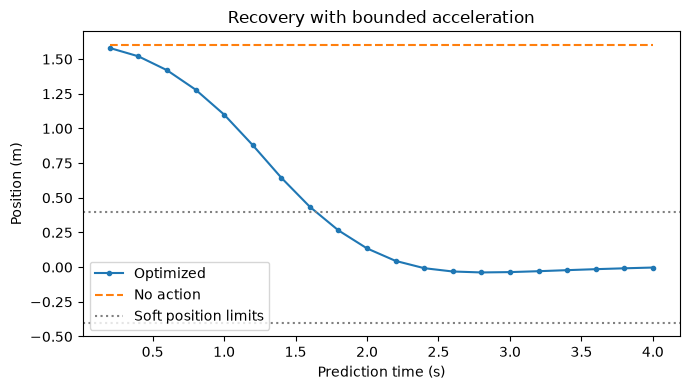

In [6]:
# Position and its soft limits share meters; no-action is a physical reference.
times = np.arange(1, 21) * 0.2
no_action = predict_states([1.6, 0.0], np.zeros(20))
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(times, prediction[:, 0], marker="o", markersize=3, label="Optimized")
ax.plot(times, no_action[:, 0], linestyle="--", label="No action")
ax.axhline(0.4, color="gray", linestyle=":", label="Soft position limits")
ax.axhline(-0.4, color="gray", linestyle=":")
ax.set(xlabel="Prediction time (s)", ylabel="Position (m)", title="Recovery with bounded acceleration")
ax.legend()
fig.tight_layout()
plt.show()


The optimized position moves toward the desired interval over several control steps, while doing nothing leaves the initial offset unchanged. Early position violation is compatible with this policy, not evidence that the hard actuator row was relaxed. The figure is an open-loop prediction under the stated model; it does not include measurement noise, an independent plant, estimation error or subsequent disturbance impulses. Those limitations matter before interpreting recovery as operational assurance.


Reuse is permitted because a new measured state changes q and the shifted state bounds but leaves P, A and penalty weights fixed. Construct a workspace once, then update it using the first predicted state as an illustrative next measurement. This is a deterministic model step, not a claim that the real state will equal its forecast. The update API validates vector shapes and finite-side structure before changing the native workspace.


In [7]:
# Preserve factorization and warm state only across the documented vector changes.
workspace = PreparedSolver(problem, "asymmetric", **accurate)
next_problem = mpc(True, True, float(prediction[0, 0]), float(prediction[0, 1]))
workspace.update(q=next_problem.q, lower=next_problem.lower, upper=next_problem.upper)
next_result = workspace.solve()
print("Vector updates:", workspace.update_count)
print(f"Next-state first acceleration: {next_result['x'][0]:.6f} m/s²")


Vector updates: 1
Next-state first acceleration: -1.000000 m/s²


Inspect the controls themselves as a separate acceleration-valued figure. Compare the initial horizon with the shifted-state horizon to see what was reused and what changed. Numerical agreement of the static formulation does not imply that successive controls should be identical: the state input and remaining recovery problem have changed. The hard lines remain fixed because the physical actuator policy did not change with the measurement.


Each acceleration acts over its full sampling interval, beginning at time zero. Both horizons use their own relative time origin; predicted positions are timestamped at interval ends.

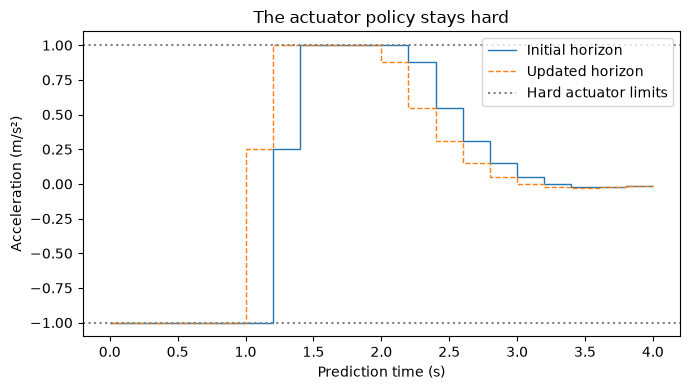

In [8]:
# A separate axis avoids mixing actuator units with the position plot.
control_edges = np.arange(len(native["x"]) + 1) * 0.2
fig, ax = plt.subplots(figsize=(7, 4))
ax.stairs(native["x"], control_edges, baseline=None, label="Initial horizon")
ax.stairs(next_result["x"], control_edges, baseline=None, linestyle="--", label="Updated horizon")
ax.axhline(1.0, color="gray", linestyle=":", label="Hard actuator limits")
ax.axhline(-1.0, color="gray", linestyle=":")
ax.set(xlabel="Prediction time (s)", ylabel="Acceleration (m/s²)", title="The actuator policy stays hard")
ax.legend()
fig.tight_layout()
plt.show()


Both control sequences remain within the declared actuator interval, even while their predicted positions initially violate a soft target. The first controls saturate because moving toward the target is valuable and acceleration is limited. Later differences arise from the updated state rather than from modifying weights. The plot demonstrates model-level policy preservation for these computed horizons; it cannot demonstrate robustness to disturbances that were never supplied to either solve.


## Results

**Answer:** The first acceleration is -1.000000 m/s² and the first predicted position is 1.580000 m. The state cannot enter the desired ±0.4 m interval immediately, but the computed control respects the hard actuator interval. The independently evaluated objective gap and KKT diagnostics printed above quantify numerical agreement separately from that physical recovery limitation.

The reusable workspace solves a changed state input without rebuilding P or A. This notebook deliberately avoids a timing claim from that single update; repeated cold/warm observations belong to the registered C12 stream and should retain initial setup as a separate cost.


## Summary

Keep three records when reviewing this class of controller: the row policy, the physical trajectory and the original-space numerical checks. Condensed dynamics, a hard actuator interval and priced state rows have different roles. If an engineering requirement forbids a state departure, reclassify that row as hard and accept the possibility of infeasibility; an arbitrarily large finite price is not an equivalent safety specification.


## References

- [OSQP numerical formulation](https://osqp.org/docs/solver/).
- [Generalized slack projections](https://arxiv.org/abs/2610.35631).
- [MathWorks, QP formulation for linear MPC](https://www.mathworks.com/help/mpc/ug/optimization-problem.html).
- Authored double-integrator model and physical predictor in this repository.
